In [1]:

from google.colab import files
from pathlib import Path
import shutil

Path('data').mkdir(exist_ok=True)
uploaded = files.upload()
source_name = next(iter(uploaded))
if not source_name.lower().endswith('.csv'):
    raise ValueError('Please upload House_Price_data.csv, not a notebook or PDF.')
shutil.move(source_name, 'data/House_Price_data.csv')
print('Dataset ready at data/House_Price_data.csv')

Saving House_Price_data.csv to House_Price_data.csv
Dataset ready at data/House_Price_data.csv


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('data/House_Price_data.csv')
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

4,600 rows x 18 columns


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [4]:
df.info()
display(df.isna().sum().rename('missing values').to_frame())
print('Exact duplicate rows:', df.duplicated().sum())
print('Zero or negative prices:', (df['price'] <= 0).sum())
display(df.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           4600 non-null   datetime64[ns]
 1   price          4600 non-null   float64       
 2   bedrooms       4600 non-null   float64       
 3   bathrooms      4600 non-null   float64       
 4   sqft_living    4600 non-null   int64         
 5   sqft_lot       4600 non-null   int64         
 6   floors         4600 non-null   float64       
 7   waterfront     4600 non-null   int64         
 8   view           4600 non-null   int64         
 9   condition      4600 non-null   int64         
 10  sqft_above     4600 non-null   int64         
 11  sqft_basement  4600 non-null   int64         
 12  yr_built       4600 non-null   int64         
 13  yr_renovated   4600 non-null   int64         
 14  street         4600 non-null   object        
 15  city           4600 n

,missing values
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0


Exact duplicate rows: 0
Zero or negative prices: 49


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,4600,NaN,NaN,NaN,2014-06-07 03:14:42.782608640,2014-05-02 00:00:00,2014-05-21 00:00:00,2014-06-09 00:00:00,2014-06-24 00:00:00,2014-07-10 00:00:00,NaN
price,4600.0,NaN,NaN,NaN,551962.988473,0.0,322875.0,460943.461539,654962.5,26590000.0,563834.702547
bedrooms,4600.0,NaN,NaN,NaN,3.40087,0.0,3.0,3.0,4.0,9.0,0.908848
bathrooms,4600.0,NaN,NaN,NaN,2.160815,0.0,1.75,2.25,2.5,8.0,0.783781
sqft_living,4600.0,NaN,NaN,NaN,2139.346957,370.0,1460.0,1980.0,2620.0,13540.0,963.206916
sqft_lot,4600.0,NaN,NaN,NaN,14852.516087,638.0,5000.75,7683.0,11001.25,1074218.0,35884.436145
floors,4600.0,NaN,NaN,NaN,1.512065,1.0,1.0,1.5,2.0,3.5,0.538288
waterfront,4600.0,NaN,NaN,NaN,0.007174,0.0,0.0,0.0,0.0,1.0,0.084404
view,4600.0,NaN,NaN,NaN,0.240652,0.0,0.0,0.0,0.0,4.0,0.778405
condition,4600.0,NaN,NaN,NaN,3.451739,1.0,3.0,3.0,4.0,5.0,0.67723


In [6]:
df['street'] = df['street'].astype('string').str.strip()
df['city'] = df['city'].astype('string').str.strip()
df['statezip'] = df['statezip'].astype('string').str.strip()
df['country'] = df['country'].astype('string').str.strip()
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.to_period('M').astype(str)
df['home_age_at_sale'] = df['date'].dt.year - df['yr_built']
df['has_basement'] = (df['sqft_basement'] > 0).astype(int)
df['was_renovated'] = (df['yr_renovated'] > 0).astype(int)
invalid_price = df['price'] <= 0
analysis = df.loc[~invalid_price].copy()
print(f'Rows retained for price analysis: {len(analysis):,} / {len(df):,}')
print(f'Non-positive prices excluded: {invalid_price.sum():,}')
from pathlib import Path
Path("outputs").mkdir(parents=True, exist_ok=True)
analysis.to_csv('outputs/cleaned_house_prices.csv', index=False)
analysis.head()

Rows retained for price analysis: 4,551 / 4,600
Non-positive prices excluded: 49


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,yr_renovated,street,city,statezip,country,sale_year,sale_month,home_age_at_sale,has_basement,was_renovated
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,...,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA,2014,2014-05,59,0,1
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,...,0,709 W Blaine St,Seattle,WA 98119,USA,2014,2014-05,93,1,0
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,...,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA,2014,2014-05,48,0,0
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,...,0,857 170th Pl NE,Bellevue,WA 98008,USA,2014,2014-05,51,1,0
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,...,1992,9105 170th Ave NE,Redmond,WA 98052,USA,2014,2014-05,38,1,1


In [8]:
from math import exp, lgamma, log, sqrt, erfc

def _beta_fraction(a, b, x):
    qab, qap, qam = a+b, a+1, a-1
    c, d = 1.0, 1.0-qab*x/qap
    d = 1e-300 if abs(d) < 1e-300 else 1.0/d
    h = d
    for m in range(1, 201):
        m2 = 2*m
        aa = m*(b-m)*x/((qam+m2)*(a+m2))
        d = 1.0 + aa*d; d = 1e-300 if abs(d) < 1e-300 else d
        c = 1.0 + aa/c; c = 1e-300 if abs(c) < 1e-300 else c
        d = 1.0/d; h *= d*c
        aa = -(a+m)*(qab+m)*x/((a+m2)*(qap+m2))
        d = 1.0 + aa*d; d = 1e-300 if abs(d) < 1e-300 else d
        c = 1.0 + aa/c; c = 1e-300 if abs(c) < 1e-300 else c
        d = 1.0/d
        delta = d*c; h *= delta
        if abs(delta-1.0) < 3e-14:
            break
    return h

def _regularized_beta(x, a, b):
    if x <= 0: return 0.0
    if x >= 1: return 1.0
    bt = exp(lgamma(a+b)-lgamma(a)-lgamma(b)+a*log(x)+b*log1p_neg(x))
    if x < (a+1)/(a+b+2):
        return bt*_beta_fraction(a,b,x)/a
    return 1-bt*_beta_fraction(b,a,1-x)/b

def log1p_neg(x):
    # stable log(1-x) for x in [0,1)
    import math
    return math.log1p(-x)

def t_two_sided_p(t, df):
    return _regularized_beta(df/(df+t*t), df/2, .5)

def t_critical_975(df):
    lo, hi = 0.0, 10.0
    for _ in range(70):
        mid = (lo+hi)/2
        if t_two_sided_p(mid, df) > .05: lo = mid
        else: hi = mid
    return (lo+hi)/2

def f_right_tail_p(f_value, df_num, df_den):
    x = df_den/(df_den+df_num*f_value)
    return _regularized_beta(x, df_den/2, df_num/2)

# Welch t-test: basement vs. no basement
has_basement = analysis['sqft_basement'].gt(0)
basement = analysis.loc[has_basement, 'price']
no_basement = analysis.loc[~has_basement, 'price']
t_stat = (basement.mean()-no_basement.mean()) / np.sqrt(basement.var(ddof=1)/len(basement) + no_basement.var(ddof=1)/len(no_basement))
mean_diff = basement.mean() - no_basement.mean()
se_diff = np.sqrt(basement.var(ddof=1)/len(basement) + no_basement.var(ddof=1)/len(no_basement))
df_welch = (basement.var(ddof=1)/len(basement) + no_basement.var(ddof=1)/len(no_basement))**2 / (
    (basement.var(ddof=1)/len(basement))**2/(len(basement)-1) +
    (no_basement.var(ddof=1)/len(no_basement))**2/(len(no_basement)-1))
tcrit = t_critical_975(df_welch)
t_p = t_two_sided_p(abs(t_stat), df_welch)
ci_low, ci_high = mean_diff - tcrit*se_diff, mean_diff + tcrit*se_diff
pooled_sd = np.sqrt(((len(basement)-1)*basement.var(ddof=1) + (len(no_basement)-1)*no_basement.var(ddof=1)) /
                     (len(basement)+len(no_basement)-2))
cohens_d = mean_diff / pooled_sd

# Chi-square: basement status x above-median price
above_median = analysis['price'] > analysis['price'].median()
contingency = pd.crosstab(has_basement, above_median)
observed = contingency.to_numpy()
row_totals, col_totals = observed.sum(axis=1), observed.sum(axis=0)
expected = np.outer(row_totals, col_totals) / observed.sum()
chi2 = ((observed-expected)**2/expected).sum()
chi_dof = (observed.shape[0]-1)*(observed.shape[1]-1)
chi_p = erfc(sqrt(chi2/2)) if chi_dof == 1 else float('nan')
cramers_v = np.sqrt(chi2 / contingency.to_numpy().sum())

# One-way ANOVA across condition ratings
condition_groups = [g['price'].to_numpy() for _,g in analysis.groupby('condition') if len(g)>1]
f_stat = (sum(len(g)*(g.mean()-analysis['price'].mean())**2 for g in condition_groups)/(len(condition_groups)-1)) / (
    sum(((g-g.mean())**2).sum() for g in condition_groups)/(len(analysis)-len(condition_groups)))
anova_p = f_right_tail_p(f_stat, len(condition_groups)-1, len(analysis)-len(condition_groups))
grand_mean = analysis['price'].mean()
ss_between = sum(len(g)*(g.mean()-grand_mean)**2 for g in condition_groups)
eta_squared = ss_between / ((analysis['price']-grand_mean)**2).sum()

print('WELCH T-TEST: basement minus no-basement mean price')
print(f'Group sizes: {len(basement):,} vs {len(no_basement):,}')
print(f'Mean difference: ${mean_diff:,.0f}; 95% CI [${ci_low:,.0f}, ${ci_high:,.0f}]')
print(f't={t_stat:.3f}; df={df_welch:.1f}; p={t_p:.4g}; Cohen d={cohens_d:.3f}')
print('Decision:', 'Reject H0' if t_p < .05 else 'Fail to reject H0')
print('\nCHI-SQUARE: basement status x above-median price')
display(contingency.rename(index={False:'No basement',True:'Basement'}, columns={False:'At/below median',True:'Above median'}))
print(f'chi-square={chi2:.3f}; df={chi_dof}; p={chi_p:.4g}; Cramers V={cramers_v:.3f}; min expected={expected.min():.1f}')
print('Decision:', 'Reject H0' if chi_p < .05 else 'Fail to reject H0')
print('\nONE-WAY ANOVA: mean price by condition rating')
print(f'F={f_stat:.3f}; p={anova_p:.4g}; eta-squared={eta_squared:.3f}')
print('Decision:', 'Reject H0' if anova_p < .05 else 'Fail to reject H0')
print('ANOVA is an overall test; it does not identify which pairs differ.')

WELCH T-TEST: basement minus no-basement mean price
Group sizes: 1,833 vs 2,718
Mean difference: $129,793; 95% CI [$97,268, $162,319]
t=7.823; df=4195.9; p=6.456e-15; Cohen d=0.232
Decision: Reject H0

CHI-SQUARE: basement status x above-median price


price,At/below median,Above median
sqft_basement,,
No basement,1537,1181
Basement,749,1084


chi-square=107.759; df=1; p=3.036e-25; Cramers V=0.154; min expected=912.3
Decision: Reject H0

ONE-WAY ANOVA: mean price by condition rating
F=4.832; p=0.0006885; eta-squared=0.004
Decision: Reject H0
ANOVA is an overall test; it does not identify which pairs differ.


In [9]:
print('Median price:', f'${analysis.price.median():,.0f}')
print('Mean price:', f'${analysis.price.mean():,.0f}')
display(analysis[['price','sqft_living','sqft_lot','bedrooms','bathrooms']].describe().T)
city_summary = (analysis.groupby('city').agg(sales=('price','size'),
                 median_price=('price','median'), median_living=('sqft_living','median'))
                .query('sales >= 20').sort_values('median_price', ascending=False))
display(city_summary.head(10).round(0))

Median price: $465,000
Mean price: $557,906


,count,mean,std,min,25%,50%,75%,max
price,4551.0,557905.899138,563929.871279,7800.0,326264.285715,465000.00,657500.0,26590000.0
sqft_living,4551.0,2132.372226,955.949708,370.0,1460.000000,1970.00,2610.0,13540.0
sqft_lot,4551.0,14835.280598,35964.077825,638.0,5000.000000,7680.00,10978.0,1074218.0
bedrooms,4551.0,3.394639,0.904595,0.0,3.000000,3.00,4.0,9.0
bathrooms,4551.0,2.155021,0.776351,0.0,1.750000,2.25,2.5,8.0


,sales,median_price,median_living
city,,,
Mercer Island,82,950467.0,3055.0
Bellevue,281,725000.0,2450.0
Sammamish,171,668500.0,2790.0
Redmond,235,638000.0,2380.0
Newcastle,33,602500.0,2550.0
Woodinville,114,562450.0,2615.0
Issaquah,186,561000.0,2270.0
Snoqualmie,69,536751.0,2500.0
Kirkland,187,522000.0,2020.0


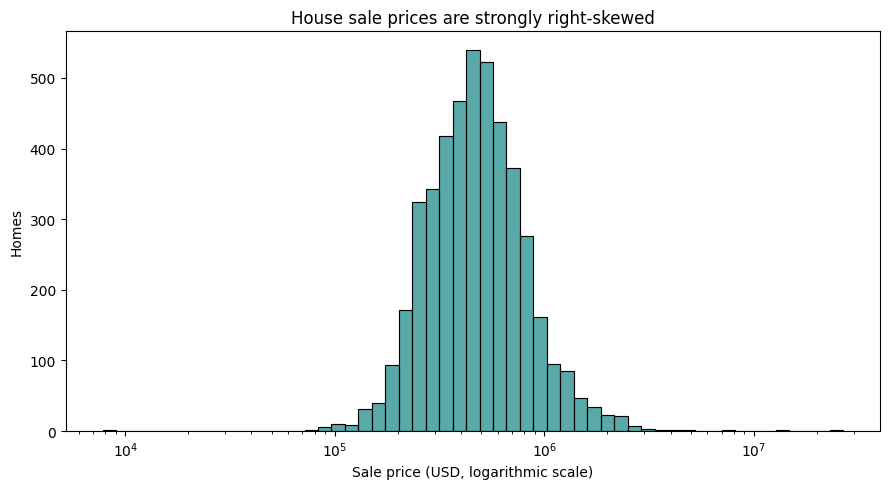

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(analysis['price'], bins=55, color='#218C8D', log_scale=(True, False))
plt.xlabel('Sale price (USD, logarithmic scale)'); plt.ylabel('Homes')
plt.title('House sale prices are strongly right-skewed'); plt.tight_layout(); plt.show()

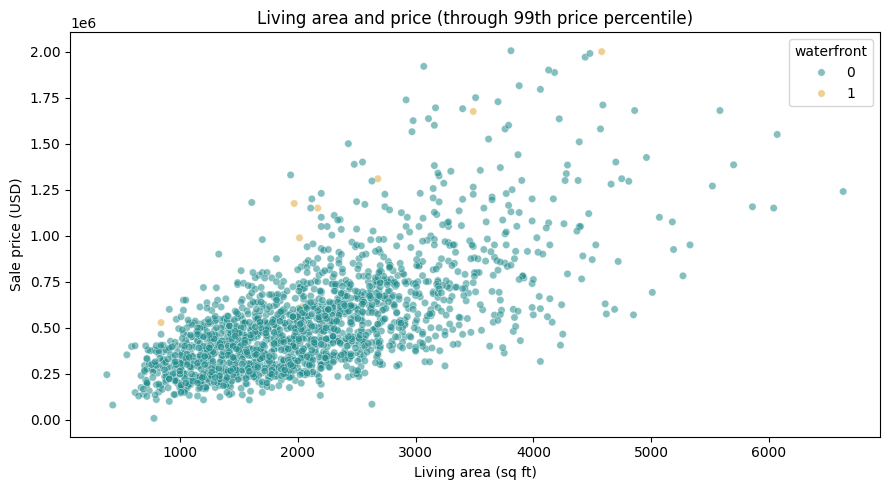

In [11]:
scatter_data = analysis.loc[analysis['price'] <= analysis['price'].quantile(.99)]
plt.figure(figsize=(9, 5))
sns.scatterplot(data=scatter_data.sample(min(1800, len(scatter_data)), random_state=42),
                x='sqft_living', y='price', hue='waterfront', alpha=.55, s=28,
                palette={0:'#218C8D', 1:'#E2A83B'})
plt.xlabel('Living area (sq ft)'); plt.ylabel('Sale price (USD)')
plt.title('Living area and price (through 99th price percentile)')
plt.tight_layout(); plt.show()

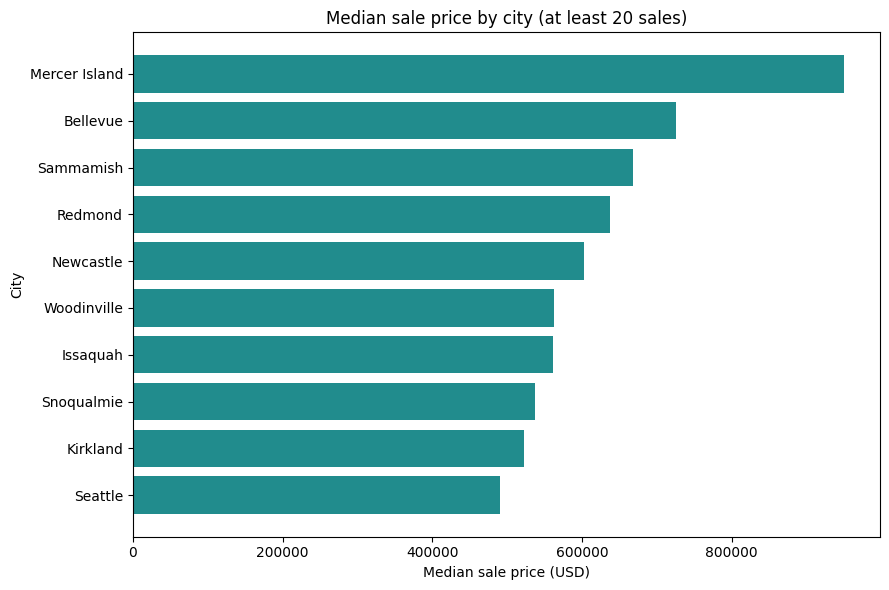

In [12]:
plt.figure(figsize=(9, 6))
plot_city = city_summary.head(10).sort_values('median_price')
plt.barh(plot_city.index, plot_city['median_price'], color='#218C8D')
plt.xlabel('Median sale price (USD)'); plt.ylabel('City')
plt.title('Median sale price by city (at least 20 sales)')
plt.tight_layout(); plt.show()

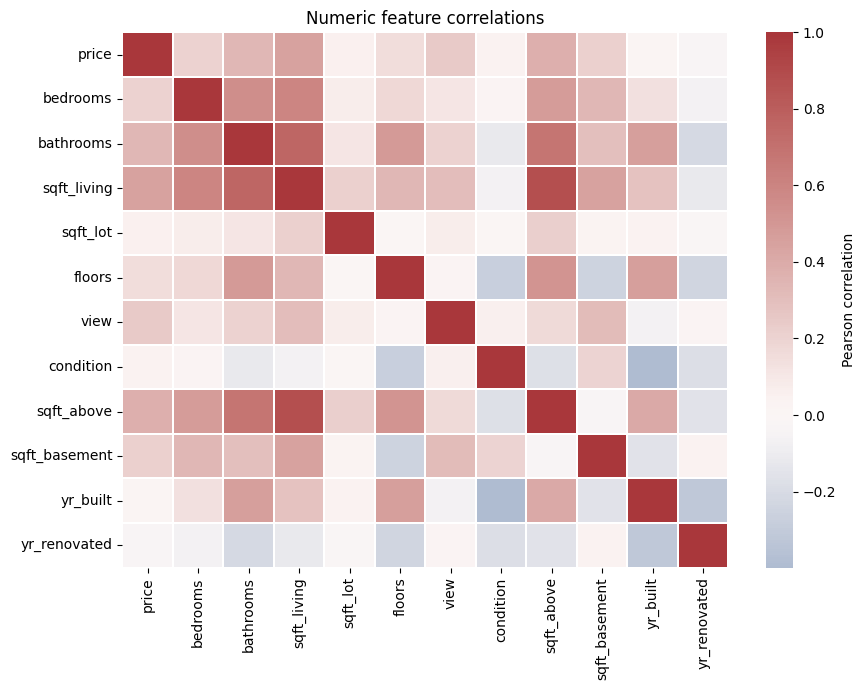

In [13]:
corr_cols = ['price','bedrooms','bathrooms','sqft_living','sqft_lot','floors',
             'view','condition','sqft_above','sqft_basement','yr_built','yr_renovated']
plt.figure(figsize=(9, 7))
sns.heatmap(analysis[corr_cols].corr(numeric_only=True), cmap='vlag', center=0,
            linewidths=.3, cbar_kws={'label':'Pearson correlation'})
plt.title('Numeric feature correlations'); plt.tight_layout(); plt.show()

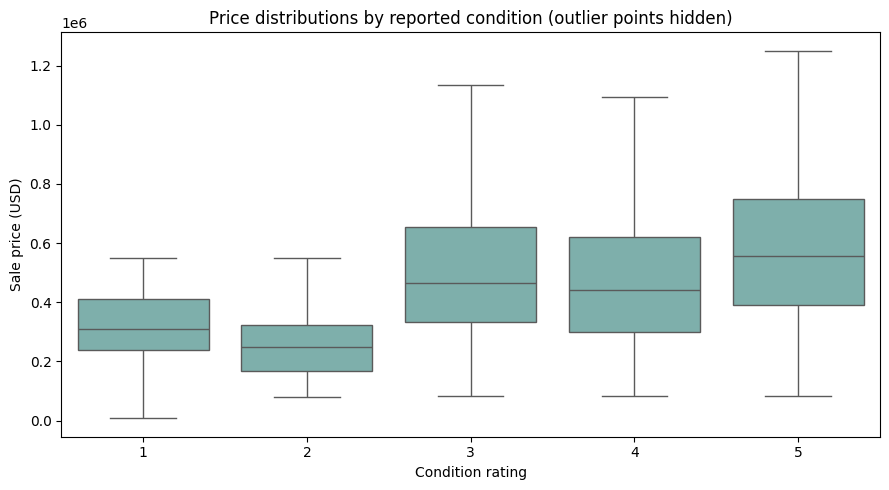

In [14]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=analysis, x='condition', y='price', color='#76B7B2', showfliers=False)
plt.xlabel('Condition rating'); plt.ylabel('Sale price (USD)')
plt.title('Price distributions by reported condition (outlier points hidden)')
plt.tight_layout(); plt.show()